# 🦌 Doñana — 1. Preparación del dataset de detección

Partimos de:
- las **etiquetas de imagen** de DONA_24 (`observations.csv`, `media.csv` del paquete CamTrap-DP): qué animal hay en cada foto;
- las **cajas de MegaDetector** (`megadetector_animal_boxes.csv`, generado en `donana_bbox_detection.ipynb`): dónde está.

Unimos ambas cosas para obtener, en cada foto con un único animal, **una caja + su especie**, y dividimos el dataset en
**train / valid / test**. Los demás notebooks (`02_train`, `03_test`, `04_data_augmentation`) leen lo que se guarda aquí.

Decisiones importantes:
1. **Una caja por imagen**: en fotos etiquetadas como "un animal" la caja de mayor confianza es la del animal. Descartamos
   las fotos cuya mejor caja es poco fiable y las que tienen **dos cajas con confianza alta** (posible segundo animal no
   etiquetado: si las dejáramos, el modelo aprendería que ese animal es fondo).
2. **Clases raras agrupadas**: lince (5 fotos), gineta (10) o meloncillo (14) no dan para entrenar ni evaluar; se agrupan en `Otros`.
3. **Split por ráfagas**: las cámaras disparan ráfagas de fotos casi idénticas. Si se reparten al azar, la misma escena cae
   en train y en test y el resultado del test es engañosamente alto. Agrupamos las fotos de la misma cámara separadas menos
   de 60 s y repartimos **ráfagas completas**, estratificando por clase.
4. **Imágenes reducidas** (lado mayor 1024 px) para que el entrenamiento no esté limitado por la lectura de JPEG grandes.

**Dónde ejecutarlo:** Google Colab. Sube `donana_data.py` y `donana_det.py` a `MyDrive/donana/` (la misma carpeta donde el
notebook de MegaDetector guardó `processed/megadetector_animal_boxes.csv`).

## 1. Configuración

In [8]:
import sys
from pathlib import Path

RUNNING_IN_COLAB = "google.colab" in sys.modules
if RUNNING_IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/donana")
    LOCAL_DIR = Path("/content")                         # disco local de Colab (rápido)
else:
    PROJECT_DIR = Path.cwd()
    LOCAL_DIR = Path.cwd()
sys.path.append(str(PROJECT_DIR))

PROCESSED_DIR = PROJECT_DIR / "processed"            # anotaciones, splits y caché comprimida
MODELS_DIR = PROJECT_DIR / "models"                  # checkpoints (en Drive, sobreviven a desconexiones)
IMAGES_DIR = LOCAL_DIR / "dona_24_1024"              # imágenes reducidas (lado mayor 1024 px)
CACHE_ZIP = PROCESSED_DIR / "dona_24_1024.zip"

DATASET_DIR = LOCAL_DIR / "dona_24"                  # dataset original de Hugging Face
CAMTRAP_PACKAGE_DIR = DATASET_DIR / "dona_24_pkg"
BOXES_CSV = PROCESSED_DIR / "megadetector_animal_boxes.csv"

# Parámetros de limpieza
MIN_BOX_CONFIDENCE = 0.5      # confianza mínima de la caja de MegaDetector para usarla como etiqueta
DROP_AMBIGUOUS = True         # descartar fotos con 2+ cajas con confianza >= AMBIGUOUS_CONFIDENCE
AMBIGUOUS_CONFIDENCE = 0.5
MIN_IMAGES_PER_CLASS = 1     # clases con menos imágenes -> "Otros" (None = mantener todas)

# Parámetros del split
EVENT_GAP_SECONDS = 60        # fotos de la misma cámara a menos de 60 s = misma ráfaga
SPLIT_GROUP_BY = "eventID"    # "eventID" (ráfagas) o "deploymentID" (test con cámaras nunca vistas, más exigente)
TEST_FRACTION = 0.20
VALID_FRACTION = 0.15         # fracción del resto (train + valid) que se usa para validación
SEED = 42

IMAGE_MAX_SIDE = 1024         # tamaño de la caché de imágenes

import donana_data as dd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pandas as pd
from PIL import Image

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
print(f"Cajas de MegaDetector: {BOXES_CSV} -> {'OK' if BOXES_CSV.exists() else 'NO ENCONTRADO'}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cajas de MegaDetector: /content/drive/MyDrive/donana/processed/megadetector_animal_boxes.csv -> OK


## 2. Descarga del dataset
Equivale a `hf download wildintelproject/dona_24 --repo-type dataset --local-dir ./dona_24`.

In [3]:
from huggingface_hub import snapshot_download

if not (DATASET_DIR / "camtrapdp-local.zip").exists():
    snapshot_download(repo_id="wildintelproject/dona_24", repo_type="dataset", local_dir=DATASET_DIR)
dd.extract_camtrap_package(DATASET_DIR, CAMTRAP_PACKAGE_DIR)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9751 files:   0%|          | 0/9751 [00:00<?, ?it/s]

## 3. Etiquetas: fotos con un único animal
Misma limpieza que en `donana_bbox_detection.ipynb` (ciervo/gamo → `Cervidae`, conejo/liebre → `Leporidae`).

In [4]:
images = dd.build_single_animal_images(DATASET_DIR, CAMTRAP_PACKAGE_DIR)
print(f"Fotos con un único animal: {len(images)}")
images["className"].value_counts().rename("imágenes").to_frame()

Fotos con un único animal: 5442


,imágenes
className,
Cervidae,2946
Sus scrofa,1236
Bos taurus,717
Leporidae,224
Vulpes vulpes,196
Meles meles,62
Equus caballus,32
Herpestes ichneumon,14
Genetta genetta,10


## 4. Unir con las cajas de MegaDetector

In [9]:
annotations, funnel = dd.build_annotations(
    images,
    BOXES_CSV,
    min_box_confidence=MIN_BOX_CONFIDENCE,
    drop_ambiguous=DROP_AMBIGUOUS,
    ambiguous_confidence=AMBIGUOUS_CONFIDENCE,
)
funnel

,Paso,Imágenes
0,Imágenes de un animal,5442
1,Con caja de MegaDetector,5411
2,Mejor caja con confianza >= 0.5,5349
3,Sin 2ª caja con confianza >= 0.5,5190


## 5. Clases

In [10]:
annotations = dd.merge_rare_classes(annotations, MIN_IMAGES_PER_CLASS)
CLASS_NAMES = dd.class_names_from(annotations)
print("Clases (label = posición + 1; 0 = fondo):")
for i, name in enumerate(CLASS_NAMES, start=1):
    print(f"  {i}: {name}")
(
    annotations.groupby(["label_name", "className"]).size().rename("imágenes").to_frame()
    .sort_values("imágenes", ascending=False)
)

Clases (label = posición + 1; 0 = fondo):
  1: Cérvido
  2: Jabalí
  3: Vaca
  4: Lepórido
  5: Zorro
  6: Tejón
  7: Caballo
  8: Meloncillo
  9: Gineta
  10: Lince


,,imágenes
label_name,className,
Cérvido,Cervidae,2773
Jabalí,Sus scrofa,1221
Vaca,Bos taurus,671
Lepórido,Leporidae,212
Zorro,Vulpes vulpes,195
Tejón,Meles meles,61
Caballo,Equus caballus,30
Meloncillo,Herpestes ichneumon,12
Gineta,Genetta genetta,10


## 6. Ráfagas y split train / valid / test

In [11]:
annotations = dd.assign_events(annotations, gap_seconds=EVENT_GAP_SECONDS)
print(f"{len(annotations)} imágenes en {annotations['eventID'].nunique()} ráfagas "
      f"de {annotations['deploymentID'].nunique()} cámaras")
print(f"Imágenes por ráfaga: media {annotations.groupby('eventID').size().mean():.1f}, "
      f"máx. {annotations.groupby('eventID').size().max()}")

annotations = dd.split_dataset(
    annotations, test_fraction=TEST_FRACTION, valid_fraction=VALID_FRACTION, group_by=SPLIT_GROUP_BY, seed=SEED
)
leaks = (annotations.groupby(SPLIT_GROUP_BY)["split"].nunique() > 1).sum()
print(f"Grupos repartidos en más de un split (debe ser 0): {leaks}")
dd.split_summary(annotations)

5190 imágenes en 1004 ráfagas de 36 cámaras
Imágenes por ráfaga: media 5.2, máx. 106
Grupos repartidos en más de un split (debe ser 0): 0


split,train,valid,test,Total
label_name,,,,
Cérvido,1966,320,487,2773
Jabalí,719,104,398,1221
Vaca,509,44,118,671
Lepórido,150,26,36,212
Zorro,152,14,29,195
Tejón,48,6,7,61
Caballo,23,6,1,30
Meloncillo,9,1,2,12
Gineta,6,1,3,10


## 7. Caché de imágenes reducidas + día / noche
La primera vez tarda unos minutos. Se guarda un `.zip` en Drive para que los demás notebooks no tengan que volver a descargar el dataset.

In [12]:
annotations = dd.cache_resized_images(annotations, DATASET_DIR, IMAGES_DIR, max_side=IMAGE_MAX_SIDE)
if not CACHE_ZIP.exists():
    dd.zip_directory(IMAGES_DIR, CACHE_ZIP)
print(annotations[["width", "height"]].value_counts().head())
pd.crosstab(annotations["label_name"], annotations["lighting"])

Caché:   0%|          | 0/5190 [00:00<?, ?it/s]

width  height
1024   576       5190
Name: count, dtype: int64


lighting,día,noche (IR)
label_name,,
Caballo,7,23
Cérvido,1665,1108
Gineta,0,10
Jabalí,433,788
Lepórido,5,207
Lince,0,5
Meloncillo,11,1
Tejón,0,61
Vaca,461,210


## 8. Comprobación visual

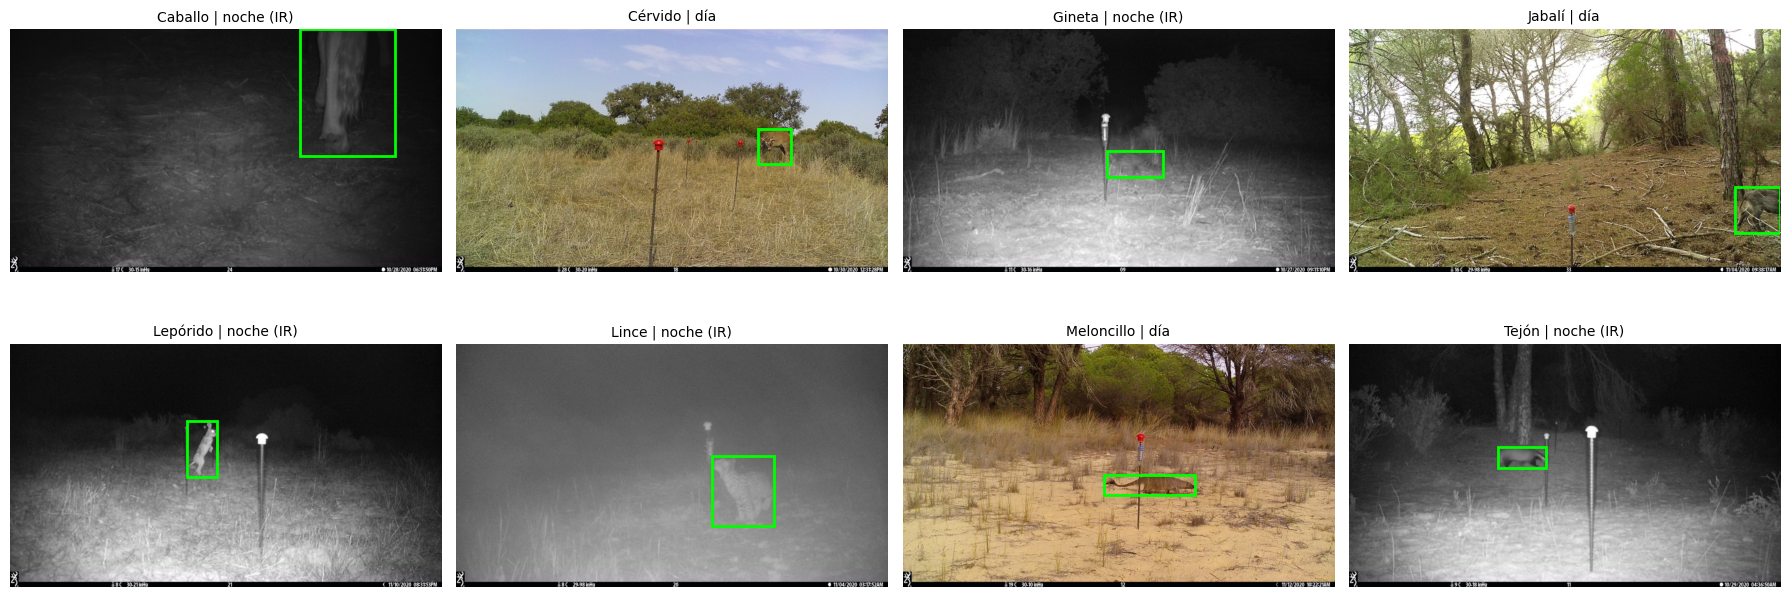

In [13]:
sample = annotations[annotations["split"] == "train"].groupby("label_name").sample(1, random_state=SEED)
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax in axes.flat:
    ax.axis("off")
for ax, row in zip(axes.flat, sample.itertuples()):
    with Image.open(IMAGES_DIR / row.filePath) as im:
        w, h = im.size
        ax.imshow(im)
    ax.add_patch(patches.Rectangle((row.x_min * w, row.y_min * h), (row.x_max - row.x_min) * w,
                                   (row.y_max - row.y_min) * h, fill=False, edgecolor="lime", linewidth=2))
    ax.set_title(f"{row.label_name} | {row.lighting}", fontsize=10)
plt.tight_layout()
plt.show()

## 9. Guardar

In [14]:
dd.save_dataset(
    annotations,
    PROCESSED_DIR,
    extra_info={
        "image_max_side": IMAGE_MAX_SIDE,
        "min_box_confidence": MIN_BOX_CONFIDENCE,
        "drop_ambiguous": DROP_AMBIGUOUS,
        "min_images_per_class": MIN_IMAGES_PER_CLASS,
        "split_group_by": SPLIT_GROUP_BY,
        "seed": SEED,
    },
)
print(sorted(p.name for p in PROCESSED_DIR.iterdir()))

['annotations.csv', 'annotations_test.csv', 'annotations_train.csv', 'annotations_valid.csv', 'dataset_info.json', 'dona_24_1024.zip', 'megadetector_animal_boxes.csv']
